# 02 · Extensões de domínio

**Objetivo:** ver como cada área da fábrica acrescenta seu vocabulário **sem redefinir o núcleo**. Produção, manutenção, qualidade, energia e estoque são arquivos separados que importam `core.ttl` e apenas adicionam classes e relações.

Por que separar? Porque cada domínio tem um dono diferente (PCP, manutenção, qualidade, utilidades, almoxarifado) e evolui em ritmo diferente. O núcleo é o acordo mínimo entre eles.

### Antes de começar

| | |
|---|---|
| **Para quem** | Quem entendeu o núcleo e quer ver como áreas diferentes da fábrica compartilham o mesmo modelo. |
| **Pré-requisitos** | Notebook 01. |
| **Tempo** | 25 minutos |

**Ao final você consegue:**

- Explicar por que cada domínio fica num arquivo separado que importa o núcleo.
- Identificar, no esquema, onde cada extensão se liga ao núcleo.
- Dizer o que uma parada, uma corrida de produção e uma inspeção herdam de `Event`.
- Ler três registros de sistemas diferentes e apontar o que os conecta.

**Onde isso aparece na fábrica:** PCP, manutenção, qualidade e utilidades têm donos, sistemas e ritmos de mudança diferentes. Um modelo modular deixa cada área evoluir a sua parte sem quebrar as outras.

**Uma analogia para guardar:** O núcleo é a tomada padrão da casa. Cada domínio é um aparelho diferente, mas todos usam o mesmo plugue. Você pode trocar a geladeira sem refazer a instalação elétrica.

> **Como estudar:** rode uma célula por vez. Sempre que aparecer **Pare e preveja**, responda mentalmente antes de executar. Errar a previsão é o que faz o conceito fixar.

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
pd.set_option("display.max_colwidth", 80)
from lab.graph import load_ontology, load_plant, query, MFG, PRD, MNT, QA, NRG, INV, ID
from lab.graph import DOMAINS
from rdflib import OWL, RDFS, RDF

## 1. O que cada extensão traz

> **Pare e preveja.** Parada de máquina, corrida de produção e inspeção de qualidade vêm de sistemas diferentes. De qual classe do núcleo todas deveriam herdar para poderem ser cruzadas?

In [2]:
linhas = []
nucleo = load_ontology(domains=[])
for d in DOMAINS:
    g = load_ontology(domains=[d])
    novas = set(g.subjects(RDF.type, OWL.Class)) - set(nucleo.subjects(RDF.type, OWL.Class))
    rels = [p for p in g.subjects(RDF.type, OWL.ObjectProperty) if (p, None, None) not in nucleo]
    herda = sorted({str(g.value(c, RDFS.subClassOf)).split("#")[-1] for c in novas if g.value(c, RDFS.subClassOf)})
    linhas.append({"domínio": d, "classes novas": ", ".join(sorted(str(c).split("#")[-1] for c in novas)),
                   "relações novas": len(rels), "estende do núcleo": ", ".join(herda)})
pd.DataFrame(linhas)

,domínio,classes novas,relações novas,estende do núcleo
0,production,"Changeover, Lot, Product, ProductionRun, Shift, WorkOrder",6,Event
1,maintenance,"Component, CorrectiveOrder, Downtime, FailureMode, MaintenanceOrder, Mainten...",7,"Asset, Event, MaintenanceOrder"
2,quality,"Characteristic, DefectType, Finding, Inspection, Measurement, NonConformance...",8,Event
3,energy,"Consumption, EnergyBaseline, EnergyCarrier, EnergyMeter",4,"DataPoint, Event"
4,inventory,"Material, MaterialLot, StockItem, StorageLocation, Supplier",6,


**Leitura**

* `ProductionRun`, `Downtime`, `MaintenanceOrder`, `Inspection` e `Consumption` estendem `Event` do núcleo: todos herdam **quando** e **onde** (`startTime`, `endTime`, `occurredOn`). É isso que permite cruzar paradas com corridas de produção pelo tempo.
* `Component` estende `Asset`: um rolamento entra na hierarquia ISA-95 abaixo da máquina.
* `EnergyMeter` estende `DataPoint`: um medidor tem tópico no UNS como qualquer tag.

## 2. O esquema completo como grafo

Cada caixa é uma classe, cada seta cheia é uma relação (`domain → range`) e cada seta tracejada é `subClassOf`. As molduras agrupam por domínio.

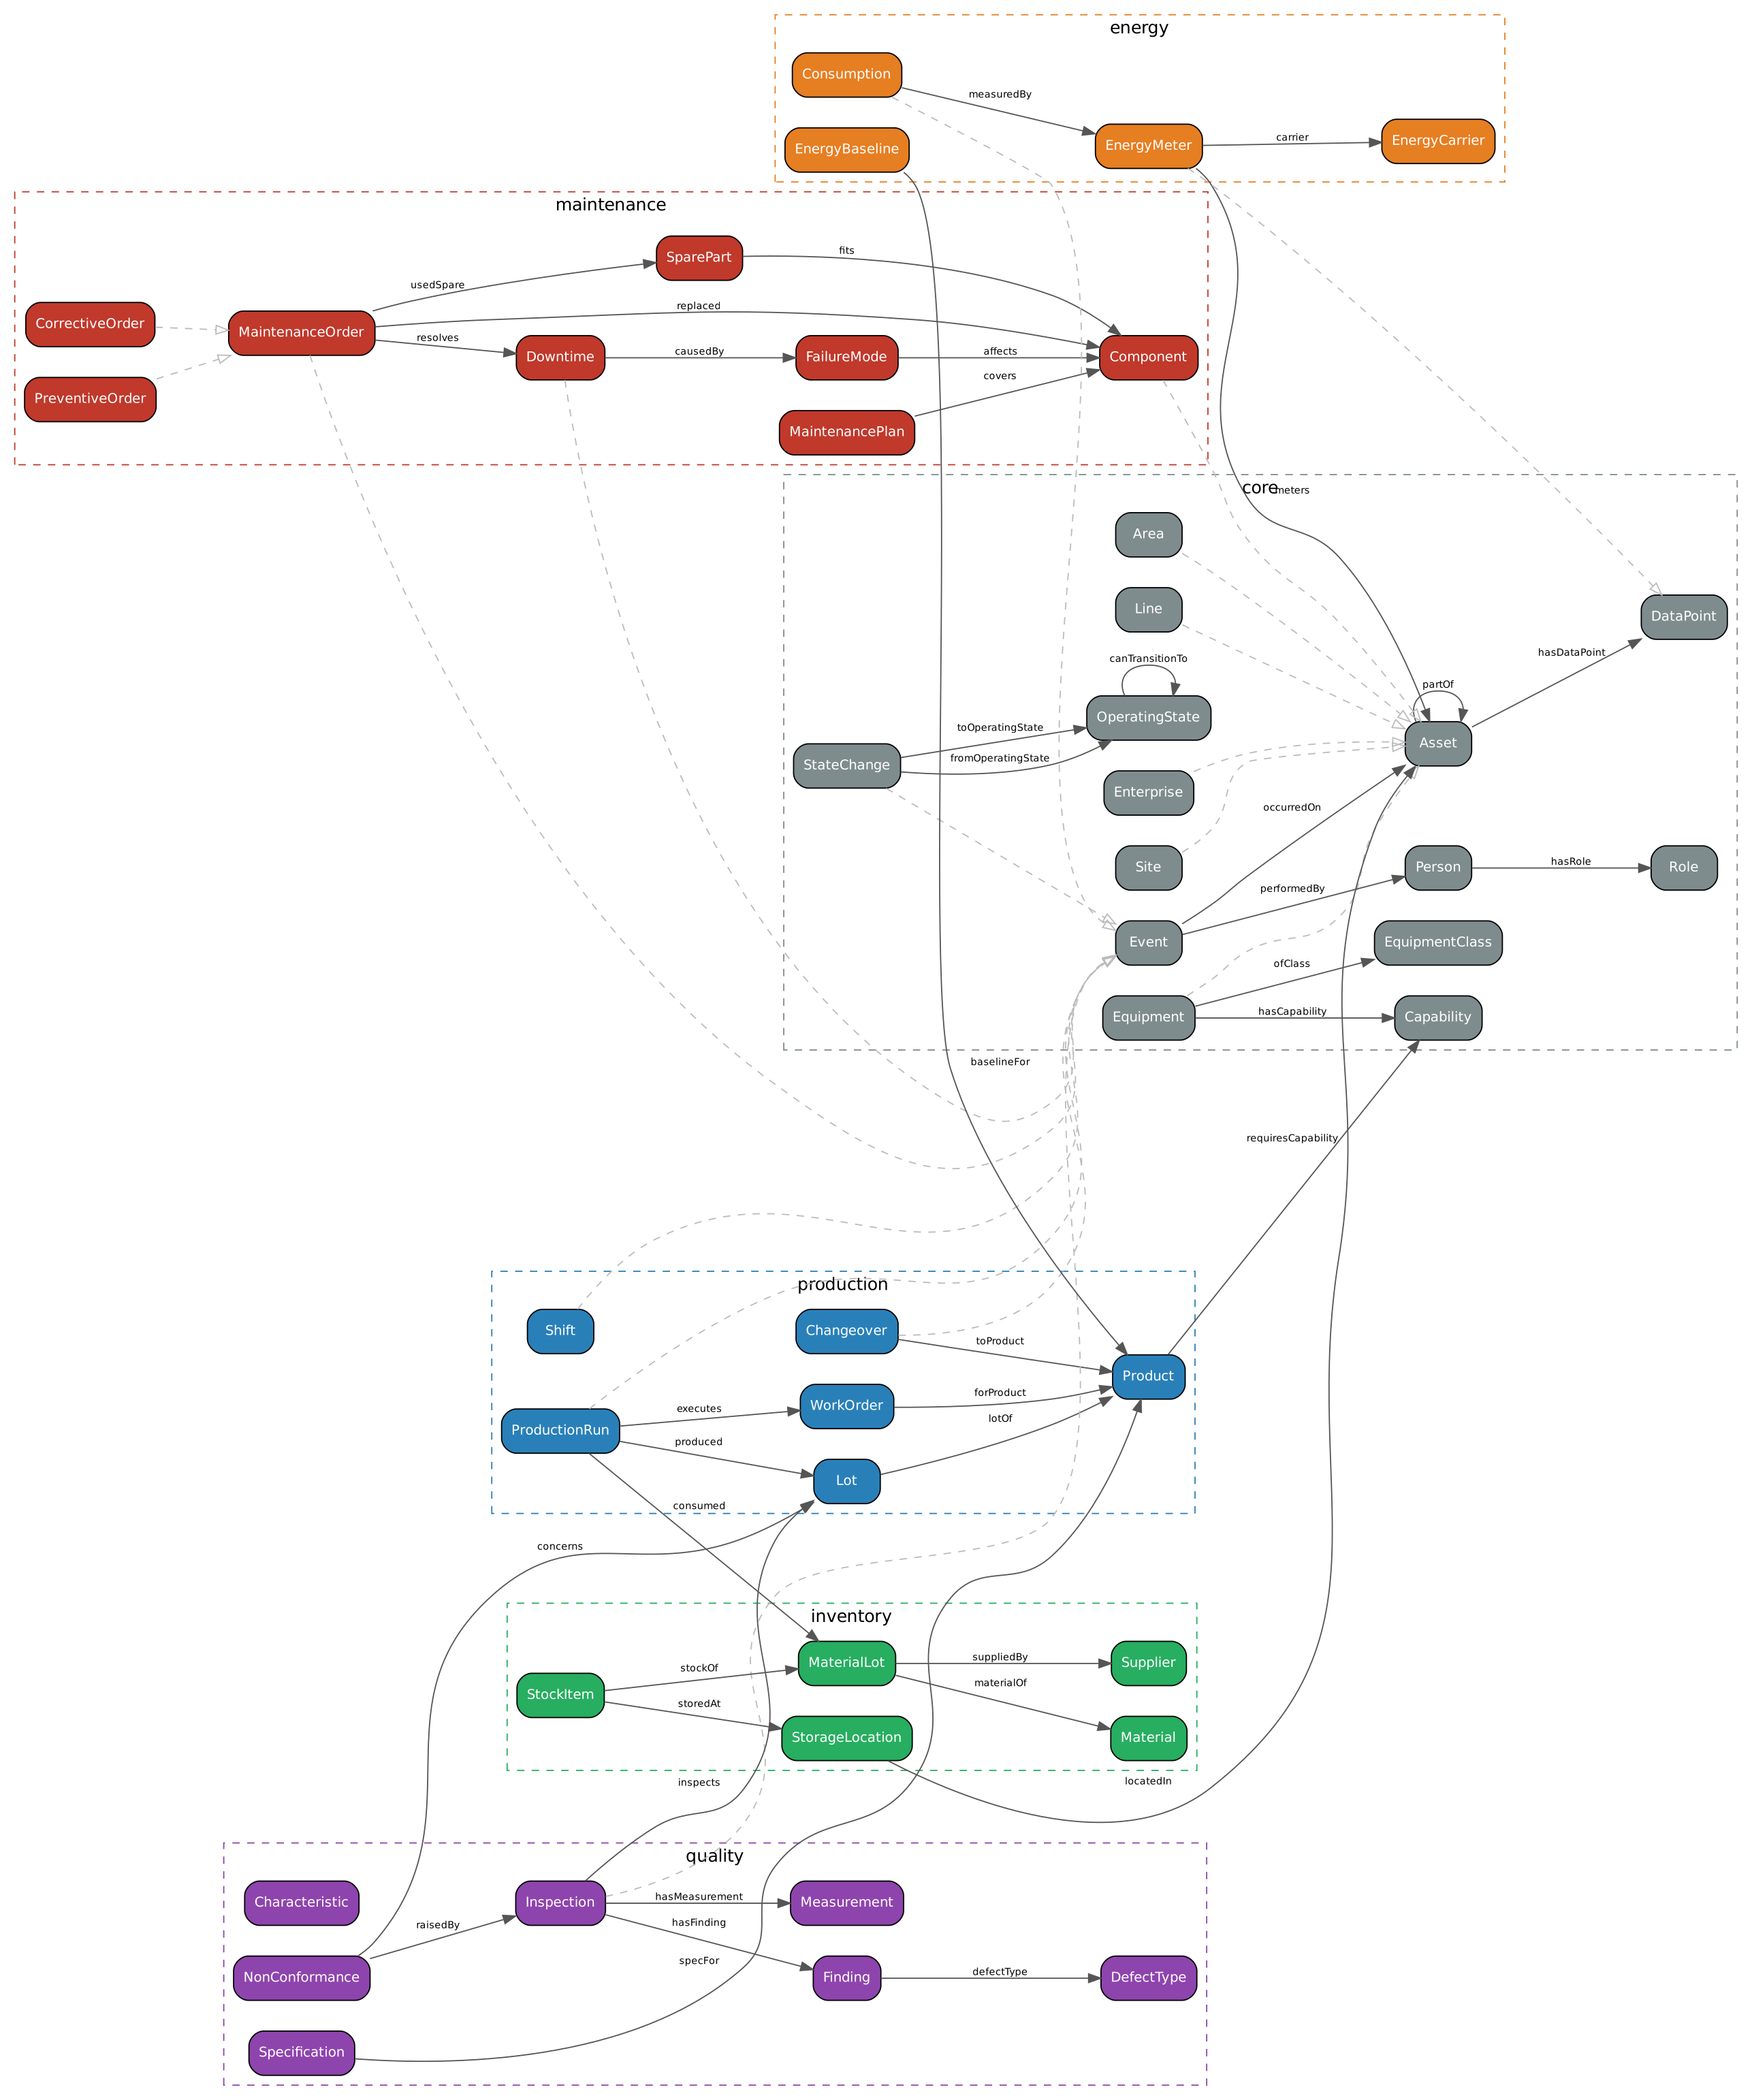

In [3]:
from IPython.display import Image
from lab import figures
Image(filename=figures.render(figures.schema_dot(load_ontology()), "schema"))

Todas as extensões convergem para os nós cinza do núcleo (`Equipment`, `Event`, `Asset`, `DataPoint`). É essa convergência que faz o grafo ser **um** e não cinco bancos de dados lado a lado.

## 3. Como os domínios aparecem nos dados

In [4]:
g = load_plant()
contagem = query(g, '''
SELECT ?classe (COUNT(?x) AS ?instancias) WHERE {
  ?x a ?c . FILTER(STRSTARTS(STR(?x), STR(id:)))
  BIND(REPLACE(STR(?c), "^.*/(.*)$", "$1") AS ?classe)
} GROUP BY ?classe ORDER BY ?classe''')
pd.DataFrame(contagem)

,classe,instancias
0,core#Area,2
1,core#Capability,5
2,core#DataPoint,27
3,core#Enterprise,1
4,core#Equipment,9
5,core#EquipmentClass,3
6,core#Line,3
7,core#Person,2
8,core#Role,2
9,core#Site,2


## 4. Um registro de cada domínio, lado a lado

Uma corrida de produção, a parada que aconteceu durante ela, e a inspeção do lote que ela gerou. Três sistemas diferentes no mundo real (MES, CMMS, QMS), três nós ligados aqui.

> **Pare e preveja.** Três registros: uma corrida, uma parada e uma inspeção. Sem nenhuma tabela de junção, o que precisa ser igual entre a corrida e a parada para sabermos que aconteceram juntas?

In [5]:
for iri in ["run/R-1042", "downtime/D-001", "inspection/Q-1042"]:
    print(f"--- {iri}")
    for p, o in sorted(g.predicate_objects(ID[iri])):
        print(f"   {g.namespace_manager.normalizeUri(p):<18} {str(o).split('/id/')[-1]}")

--- run/R-1042
   rdf:type           https://w3id.org/industrial-ontology-lab/production#ProductionRun
   rdfs:label         R-1042
   mfg:endTime        2026-11-10T10:00:00+00:00
   mfg:occurredOn     acme/sao-paulo/packaging/line-1/filler-01
   mfg:startTime      2026-11-10T08:00:00+00:00
   inv:consumed       material-lot/ML-2207
   prd:executes       work-order/WO-1042
   prd:goodQty        44100
   prd:produced       lot/L-1042
   prd:rejectQty      980
--- downtime/D-001
   rdf:type           https://w3id.org/industrial-ontology-lab/maintenance#Downtime
   mfg:endTime        2026-11-10T09:15:00+00:00
   mfg:occurredOn     acme/sao-paulo/packaging/line-1/filler-01
   mfg:startTime      2026-11-10T09:00:00+00:00
   mnt:causedBy       failure-mode/seal-wear
   mnt:planned        false
--- inspection/Q-1042
   rdf:type           https://w3id.org/industrial-ontology-lab/quality#Inspection
   rdfs:label         Q-1042
   mfg:performedBy    person/bruno-reis
   qa:hasFinding      findin

**Leitura:** a corrida `R-1042` e a parada `D-001` apontam para a **mesma** enchedora (`occurredOn`), e os horários se sobrepõem. A inspeção aponta para o lote que a corrida produziu. Nenhuma tabela de junção foi criada para isso: as ligações vêm do vocabulário compartilhado.

## Resumo

* Extensões **importam** o núcleo e só **acrescentam**. Cada domínio pode ter seu dono e seu ciclo de revisão.
* Eventos de todos os domínios herdam tempo e ativo do núcleo: é por aí que se cruzam.
* O próximo passo é garantir que os dados que entram respeitem esse modelo (notebook 03).

---
## Erros comuns

- **Redefinir "máquina" em cada domínio.** Cada sistema cria seu cadastro e nada mais cruza. As extensões apontam para `Equipment` do núcleo.
- **Extensão que altera o núcleo.** Uma extensão só acrescenta. Se ela precisa mudar o núcleo, a mudança é discutida com todos.
- **Eventos sem tempo ou sem ativo.** Sem início, fim e onde ocorreu, um evento não pode ser cruzado com nenhum outro.
- **Modelar por sistema e não por significado.** A classe é `Downtime`, não `RegistroDoCMMS`. Sistemas mudam, o conceito fica.

## Teste seu entendimento

Responda antes de abrir cada resposta.

**1. Por que `Component` estende `Asset` e não uma classe nova e independente?**

<details><summary>Ver resposta</summary>

Porque assim um componente entra na hierarquia `partOf` abaixo da máquina e aparece em qualquer consulta de ativos, sem que a consulta precise conhecê-lo.

</details>

**2. O que `EnergyMeter` ganha por ser subclasse de `DataPoint`?**

<details><summary>Ver resposta</summary>

Ele já nasce com tópico no UNS, unidade e último valor, como qualquer outro ponto de dado, e ainda acrescenta a relação com o que ele mede.

</details>

**3. Qual é o custo de colocar os cinco domínios num único arquivo?**

<details><summary>Ver resposta</summary>

Toda mudança de uma área exige revisar e republicar o modelo inteiro, e ninguém sabe ao certo quem é dono de cada parte.

</details>

## Exercícios para praticar

1. Crie uma extensão mínima `safety.ttl` com uma classe `SafetyEvent` que herde de `Event`. O que ela ganha de graça?
2. No esquema desenhado, encontre o caminho que liga `Inspection` a `MaterialLot` e escreva-o em palavras.
3. Liste quais classes de cada extensão não se ligam a nada do núcleo. Elas deveriam?

## Glossário

| Termo | Significado |
|---|---|
| **owl:imports** | Declaração de que um arquivo usa os termos de outro. |
| **Domínio (domain) e contradomínio (range)** | De que tipo de coisa uma relação parte e a que tipo ela chega. |
| **Herança** | Uma subclasse recebe as relações e atributos da classe mãe. |
| **Evento** | Algo que acontece num ativo, com início e fim. |
| **Extensão de domínio** | Vocabulário de uma área específica, que acrescenta ao núcleo. |

**Próximo passo:** [03 · Contratos de dados com SHACL](03_contratos_de_dados_shacl.ipynb), para garantir que os dados que entram respeitem o modelo.